# Notebook 07 — Cấp 7 (Bonus): Hybrid AlphaGo PUCT-MCTS (`AlphaGoAgent`)

**Câu hỏi nghiên cứu trọng tâm:**
- Việc kết hợp **Policy Network (Cấp 5)** + **Dueling DQN (Cấp 6)** thành **Ensemble Neural Prior** trong cây tìm kiếm **AlphaGo PUCT-MCTS** có vượt trội rõ rệt từng mạng đơn lẻ (`5`, `6`), `MCTS` cổ điển (Cấp 4) và `Minimax d=3` (Cấp 3) dưới cùng ngân sách `0.8s/nước` hay không?

---

### Đối chiếu minh bạch theo Mục 3.2 đề cương: AlphaGo nguyên bản (Nature 2016) vs Cấp 7

| Thành phần kiến trúc | AlphaGo nguyên bản (Silver et al., 2016) | Cấp 7 (`AlphaGoAgent` của nhóm) | Trạng thái |
|---|---|---|---|
| **SL Policy Network** | CNN 13 lớp học từ ván cao thủ KGS | `TorchPolicyResNet` 4 ResBlocks × 64ch (Cấp 5, 4 kênh) | **Đã hiện thực** |
| **RL Value / Q Network** | Value CNN học từ tự chơi | `DuelingCaroDQN` 3 ResGN Blocks × 48ch (Cấp 6, Masked Mean) | **Đã hiện thực** |
| **Cây tìm kiếm PUCT-MCTS** | PUCT + FPU + nhánh định hướng Policy | PUCT + FPU + Lazy Expansion + **Ensemble Prior (Cấp 5 + Cấp 6)** + Zobrist Eval Cache | **Đã hiện thực** |
| **Giải thích quyết định** | Phân tích tỷ lệ thăm & giá trị nút | `explain_decision()` xuất `visits`, `prior`, `q_mcts`, `value_rl` + Heatmap | **Đã hiện thực** |
| **Fast Rollout Policy riêng** | Mạng tuyến tính nhỏ cho rollout 19×19 | Thay bằng đánh giá lá pha trộn `v_RL + v_heur` + bảo vệ thế cưỡng bức | *Biến thể phù hợp CPU 11×11* |
| **RL Policy Gradient + Cụm GPU/TPU** | Hàng triệu ván self-play đa luồng + Virtual Loss | Chạy đơn luồng CPU (`<= 0.8s/nước`), không huấn luyện cụm GPU | **Chưa hiện thực** *(ngoài phạm vi phần cứng)* |

> *Lưu ý thuật ngữ (Mục 3.2):* Cấp 7 là phiên bản **AlphaGo-inspired** phù hợp với Caro 11×11 và ngân sách CPU, không khẳng định tái hiện đầy đủ hệ thống cụm GPU/TPU nguyên bản.


## 1. Thiết lập môi trường, Khai báo phần cứng & Tài nguyên kết hợp (5 + 6)


In [1]:
import ctypes
import json
import math
import os
import platform
import random
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 1. CẤU HÌNH CHẾ ĐỘ CHẠY & SEED TÁI LẬP
#    - RUN_MODE = "quick": kiểm thử & benchmark nhanh (10-40 giây)
#    - RUN_MODE = "full" : chạy quy mô lớn (50-100+ ván / full training)
# ------------------------------------------------------------------
RUN_MODE = os.environ.get("CARO_NB_MODE", "quick").strip().lower()
assert RUN_MODE in ("quick", "full"), f"RUN_MODE không hợp lệ: {RUN_MODE}"

BASE_SEED = 42
# Tập seed đánh giá cuối cùng độc lập (tuyệt đối không dùng chọn siêu tham số)
FINAL_BENCHMARK_SEEDS = [9001, 9002, 9003, 9004, 9005]

# 2. Tự động nhận diện môi trường (VS Code Local vs Google Colab)
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")
    colab_proj = Path("/content/drive/MyDrive/csttnt_nang_cao/caro_ai_11x11")
    if colab_proj.exists():
        os.chdir(colab_proj)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists() and (PROJECT_ROOT.parent / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
LOGS_DIR = PROJECT_ROOT / "results" / "logs"
CHECKPOINTS_DIR = PROJECT_ROOT / "checkpoints"
DATA_DIR = PROJECT_ROOT / "data"
for _d in (TABLES_DIR, FIGURES_DIR, LOGS_DIR, CHECKPOINTS_DIR, DATA_DIR):
    _d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25


def _get_system_ram_gb() -> str:
    try:
        if platform.system() == "Windows":
            class _MemStatus(ctypes.Structure):
                _fields_ = [
                    ("dwLength", ctypes.c_ulong),
                    ("dwMemoryLoad", ctypes.c_ulong),
                    ("ullTotalPhys", ctypes.c_ulonglong),
                    ("ullAvailPhys", ctypes.c_ulonglong),
                    ("ullTotalPageFile", ctypes.c_ulonglong),
                    ("ullAvailPageFile", ctypes.c_ulonglong),
                    ("ullTotalVirtual", ctypes.c_ulonglong),
                    ("ullAvailVirtual", ctypes.c_ulonglong),
                    ("ullAvailExtendedVirtual", ctypes.c_ulonglong),
                ]
            st = _MemStatus()
            st.dwLength = ctypes.sizeof(_MemStatus)
            ctypes.windll.kernel32.GlobalMemoryStatusEx(ctypes.byref(st))
            return f"{st.ullTotalPhys / (1024**3):.1f} GB (trống {st.ullAvailPhys / (1024**3):.1f} GB)"
        with open("/proc/meminfo", encoding="utf-8") as f:
            lines = dict(line.split(":", 1) for line in f if ":" in line)
            tot = int(lines["MemTotal"].strip().split()[0]) / (1024**2)
            return f"{tot:.1f} GB"
    except Exception:
        return "N/A"


def _get_process_ram_mb() -> float:
    try:
        if platform.system() == "Windows":
            class _PMC(ctypes.Structure):
                _fields_ = [
                    ("cb", ctypes.c_ulong),
                    ("PageFaultCount", ctypes.c_ulong),
                    ("PeakWorkingSetSize", ctypes.c_size_t),
                    ("WorkingSetSize", ctypes.c_size_t),
                    ("QuotaPeakPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaPeakNonPagedPoolUsage", ctypes.c_size_t),
                    ("QuotaNonPagedPoolUsage", ctypes.c_size_t),
                    ("PagefileUsage", ctypes.c_size_t),
                    ("PeakPagefileUsage", ctypes.c_size_t),
                ]
            pmc = _PMC()
            pmc.cb = ctypes.sizeof(_PMC)
            h = ctypes.windll.kernel32.GetCurrentProcess()
            if ctypes.windll.psapi.GetProcessMemoryInfo(h, ctypes.byref(pmc), pmc.cb):
                return round(pmc.WorkingSetSize / (1024**2), 1)
        else:
            import resource
            return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0, 1)
    except Exception:
        pass
    return -1.0


# 3. Khai báo tài nguyên phần cứng (Mục 3.4 & 3.5 đề cương)
try:
    import torch
    TORCH_INFO = f"PyTorch {torch.__version__} | CUDA={torch.cuda.is_available()}"
    if torch.cuda.is_available():
        TORCH_INFO += f" ({torch.cuda.get_device_name(0)})"
except Exception:
    TORCH_INFO = "PyTorch not available"

HW_INFO = {
    "run_mode": RUN_MODE,
    "os": f"{platform.system()} {platform.release()}",
    "python": platform.python_version(),
    "cpu_cores": os.cpu_count(),
    "processor": platform.processor() or platform.machine(),
    "system_ram": _get_system_ram_gb(),
    "process_ram_mb": _get_process_ram_mb(),
    "accelerator": TORCH_INFO,
    "base_seed": BASE_SEED,
    "project_root": str(PROJECT_ROOT),
}
display(pd.DataFrame([HW_INFO]).T.rename(columns={0: "Giá trị"}))


,Giá trị
run_mode,quick
os,Windows 10
python,3.11.9
cpu_cores,20
processor,"Intel64 Family 6 Model 154 Stepping 3, Genuine..."
system_ram,15.7 GB (trống 0.3 GB)
process_ram_mb,-1.0
accelerator,PyTorch 2.15.0+cpu | CUDA=False
base_seed,42
project_root,f:\TTNTNC\Caro\caro_ai_11x11


In [2]:
from src.caro_env import CaroEnv


def wilson_ci95(successes: float, n: int) -> tuple[float, float]:
    """Khoảng tin cậy Wilson 95% cho tỷ lệ điểm Score = (W + 0.5*D) / N."""
    if n <= 0:
        return (0.0, 0.0)
    z = 1.959963984540054
    p = max(0.0, min(1.0, successes / n))
    denom = 1.0 + z * z / n
    center = (p + z * z / (2.0 * n)) / denom
    half = (z * math.sqrt((p * (1.0 - p) + z * z / (4.0 * n)) / n)) / denom
    return (max(0.0, center - half) * 100.0, min(1.0, center + half) * 100.0)


def save_raw_logs_jsonl(records: list[dict], path: Path) -> Path:
    """Lưu log thi đấu thô từng ván (.jsonl) phục vụ tái lập & phân tích định tính (Mục 3.7 & 5)."""
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        for rec in records:
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
    return path


def run_match_series(
    label: str,
    make_a,
    make_b,
    n_games: int = 20,
    openings: list[tuple[int, int]] | None = None,
    board_size: int = 11,
    win_length: int = 5,
    raw_logs_out: list[dict] | None = None,
) -> dict:
    """
    Chạy loạt ván đấu cân bằng 50/50 lượt đi trước (X) và đi sau (O).
    Ghi nhận bảng tổng hợp (W/D/L, Score%, Wilson CI95, avg_ms, p95_ms, avg_search)
    và đẩy log thô từng ván vào `raw_logs_out` nếu được truyền vào.
    """
    t0 = time.perf_counter()
    wins = draws = losses = 0
    times_a, searches_a, moves_list = [], [], []
    wx = lx = dx = wo = lo = do = 0
    x_wins_total = o_wins_total = draws_total = 0

    for g in range(n_games):
        env = CaroEnv(board_size=board_size, win_length=win_length)
        opening_used = []
        if openings:
            m1, m2 = openings[g % len(openings)]
            env.step(m1)
            env.step(m2)
            opening_used = [int(m1), int(m2)]
        agent_a = make_a(g)
        agent_b = make_b(g)
        a_side = 1 if (g % 2 == 0) else -1
        game_times_a, game_searches_a = [], []

        while not env.is_terminal():
            if env.current_player == a_side:
                act = agent_a.select_action(env)
                dt = float(getattr(agent_a, "last_move_time_ms", 0.0))
                sc = float(getattr(agent_a, "last_search_count", 0.0))
                times_a.append(dt)
                searches_a.append(sc)
                game_times_a.append(dt)
                game_searches_a.append(sc)
            else:
                act = agent_b.select_action(env)
            env.step(act)

        moves_list.append(len(env.history))
        if env.winner == 1:
            x_wins_total += 1
        elif env.winner == -1:
            o_wins_total += 1
        else:
            draws_total += 1

        if env.winner == a_side:
            wins += 1
            res_a = "win"
            if a_side == 1:
                wx += 1
            else:
                wo += 1
        elif env.winner == -a_side:
            losses += 1
            res_a = "loss"
            if a_side == 1:
                lx += 1
            else:
                lo += 1
        else:
            draws += 1
            res_a = "draw"
            if a_side == 1:
                dx += 1
            else:
                do += 1

        if raw_logs_out is not None:
            gts = sorted(game_times_a)
            gp95 = gts[int(0.95 * (len(gts) - 1))] if gts else 0.0
            raw_logs_out.append({
                "matchup": label,
                "game_index": g + 1,
                "agent_a": getattr(agent_a, "name", "AgentA"),
                "agent_b": getattr(agent_b, "name", "AgentB"),
                "agent_a_side": "X" if a_side == 1 else "O",
                "opening": opening_used,
                "winner": "X" if env.winner == 1 else ("O" if env.winner == -1 else "Draw"),
                "result_a": res_a,
                "num_moves": len(env.history),
                "avg_ms_a": round(statistics.mean(game_times_a), 3) if game_times_a else 0.0,
                "p95_ms_a": round(gp95, 3),
                "avg_search_a": round(statistics.mean(game_searches_a), 2) if game_searches_a else 0.0,
                "history": [int(m) for m in env.history],
            })

    score_pts = wins + 0.5 * draws
    score_pct = 100.0 * score_pts / max(1, n_games)
    ci_lo, ci_hi = wilson_ci95(score_pts, n_games)
    ts = sorted(times_a)
    p95 = ts[int(0.95 * (len(ts) - 1))] if ts else 0.0

    return {
        "matchup": label,
        "games": n_games,
        "wins": wins,
        "draws": draws,
        "losses": losses,
        "score_pct": round(score_pct, 2),
        "ci95_low": round(ci_lo, 2),
        "ci95_high": round(ci_hi, 2),
        "as_X": f"{wx}W-{dx}D-{lx}L",
        "as_O": f"{wo}W-{do}D-{lo}L",
        "x_win_pct": round(100.0 * x_wins_total / max(1, n_games), 1),
        "o_win_pct": round(100.0 * o_wins_total / max(1, n_games), 1),
        "avg_moves": round(statistics.mean(moves_list), 2) if moves_list else 0.0,
        "avg_ms": round(statistics.mean(times_a), 3) if times_a else 0.0,
        "p95_ms": round(p95, 3),
        "avg_search": round(statistics.mean(searches_a), 2) if searches_a else 0.0,
        "elapsed_sec": round(time.perf_counter() - t0, 2),
    }


def plot_board_heatmap(
    env: CaroEnv,
    heatmap_121: np.ndarray | None = None,
    highlight_action: int | None = None,
    title: str = "Caro 11x11",
    cbar_label: str = "Score",
    save_path: Path | None = None,
) -> None:
    """Vẽ bàn cờ Caro 11x11 kèm heatmap tùy chọn (xác suất CNN / Q-value / lượt thăm MCTS)."""
    n = env.board_size
    fig, ax = plt.subplots(figsize=(6.2, 6.0))

    if heatmap_121 is not None:
        grid = np.asarray(heatmap_121, dtype=np.float64).reshape(n, n)
        masked = np.ma.masked_where(env.board != 0, grid)
        im = ax.imshow(masked, cmap="YlOrRd", origin="upper", alpha=0.85)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=cbar_label)

    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#333333", linestyle="-", linewidth=0.8)
    ax.grid(which="major", visible=False)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    for r in range(n):
        for c in range(n):
            v = int(env.board[r, c])
            if v == 1:
                ax.plot(c, r, marker="x", markersize=13, markeredgewidth=2.6, color="#c0392b")
            elif v == -1:
                ax.plot(c, r, marker="o", markersize=11, markeredgewidth=2.2, markerfacecolor="none", color="#2471a3")

    if highlight_action is not None:
        hr, hc = divmod(int(highlight_action), n)
        ax.add_patch(plt.Rectangle((hc - 0.48, hr - 0.48), 0.96, 0.96, fill=False, edgecolor="#1e8449", linewidth=2.8))

    ax.set_title(title, fontsize=10.5, fontweight="bold")
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def plot_failure_or_decisive_game(
    raw_logs: list[dict],
    prefer_matchup: str | None = None,
    title_prefix: str = "Phân tích ván thua điển hình",
    save_path: Path | None = None,
) -> dict | None:
    """
    Tự động trích xuất 1 ván thua điển hình từ `raw_logs` (nếu không có ván thua thì chọn
    ván quyết định dài nhất), dựng lại bàn cờ kết thúc kèm số thứ tự 6 nước cuối cùng
    và đánh dấu nước sai lầm trước đòn kết liễu (Mục 3.6 — Failure Case Analysis).
    """
    pool = [r for r in raw_logs if prefer_matchup is None or prefer_matchup in r["matchup"]]
    losses = [r for r in pool if r["result_a"] == "loss"]
    target = losses[0] if losses else (max(pool, key=lambda r: r["num_moves"]) if pool else None)
    if target is None or not target["history"]:
        print("Không có ván phù hợp trong raw_logs để minh họa.")
        return None

    hist = target["history"]
    env = CaroEnv(board_size=11, win_length=5)
    for m in hist:
        env.step(int(m))

    n = env.board_size
    fig, ax = plt.subplots(figsize=(6.4, 6.2))
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#444444", linestyle="-", linewidth=0.75)
    ax.grid(which="major", visible=False)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)

    last_start = max(0, len(hist) - 6)
    for idx, act in enumerate(hist):
        r, c = divmod(int(act), n)
        p = 1 if idx % 2 == 0 else -1
        if idx == len(hist) - 1:
            ax.add_patch(plt.Rectangle((c - 0.48, r - 0.48), 0.96, 0.96, color="#f1948a", alpha=0.45))
        elif idx == len(hist) - 2:
            ax.add_patch(plt.Rectangle((c - 0.48, r - 0.48), 0.96, 0.96, color="#f9e79f", alpha=0.55))
        if p == 1:
            ax.plot(c, r, marker="x", markersize=12, markeredgewidth=2.5, color="#c0392b")
        else:
            ax.plot(c, r, marker="o", markersize=10.5, markeredgewidth=2.1, markerfacecolor="none", color="#2471a3")
        if idx >= last_start:
            ax.text(c + 0.16, r - 0.18, str(idx + 1), fontsize=8, fontweight="bold", color="#1b2631")

    kind = "THUA" if target["result_a"] == "loss" else target["result_a"].upper()
    ax.set_title(
        f"{title_prefix} ({kind}, {target['num_moves']} nước)\n"
        f"{target['matchup']} | Agent A cầm {target['agent_a_side']} | Vàng=nước áp chót, Đỏ=nước kết thúc",
        fontsize=9.5,
        fontweight="bold",
    )
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    return target


## 2. Kiểm thử tính đúng đắn, Zobrist Cache & Explainability API


In [3]:
from src.agents import (
    AlphaGoAgent,
    CNNAgent,
    MCTSAgent,
    MinimaxAgent,
    RandomAgent,
    RLAgent,
    RuleBasedAgent,
)

POLICY_CKPT = CHECKPOINTS_DIR / "05_cnn_policy_best.pt"
VALUE_CKPT = CHECKPOINTS_DIR / "06_rl_best.pt"
assert POLICY_CKPT.exists(), f"Thiếu checkpoint 5: {POLICY_CKPT}"
assert VALUE_CKPT.exists(), f"Thiếu checkpoint 6: {VALUE_CKPT}"

shared_policy = CNNAgent(model_path=POLICY_CKPT, use_tactical_shortcut=False, device="auto", seed=BASE_SEED)
shared_value = RLAgent(checkpoint_path=VALUE_CKPT, device="auto")

p_params = sum(p.numel() for p in shared_policy.torch_model.parameters())
v_params = sum(p.numel() for p in shared_value.model.parameters())
res_l7 = {
    "policy_checkpoint_l5": f"{POLICY_CKPT.name} ({POLICY_CKPT.stat().st_size/(1024**2):.2f} MB, {p_params:,} params)",
    "value_checkpoint_l6": f"{VALUE_CKPT.name} ({VALUE_CKPT.stat().st_size/(1024**2):.2f} MB, {v_params:,} params)",
    "total_parameters": f"{p_params + v_params:,}",
    "process_ram_mb": _get_process_ram_mb(),
    "device": str(shared_policy.device),
    "extra_training_time_sec": 0.0,
}
display(pd.DataFrame([res_l7]).T.rename(columns={0: "Tài nguyên Cấp 7 (Mục 3.4 & 3.5)"}))

env_mid = CaroEnv()
for m in [60, 49, 61, 38, 59, 71, 70, 80]:
    env_mid.step(m)

ag_demo = AlphaGoAgent(
    policy_agent=shared_policy,
    value_agent=shared_value,
    num_simulations=200,
    time_limit_sec=0.8,
    value_blend_alpha=0.25,
    seed=BASE_SEED,
)
chosen = ag_demo.select_action(env_mid)
exp = ag_demo.explain_decision(top_k=5)
assert chosen in env_mid.legal_actions()
print(
    f"Selected={chosen} | sims={exp['simulations']} | cache_hits={exp['cache_hits']} | "
    f"time={exp['move_time_ms']:.1f}ms | root_V_rl={exp['root_value_rl']}"
)
display(pd.DataFrame(exp["top_moves"]))


,Tài nguyên Cấp 7A (Mục 3.4 & 3.5)
policy_checkpoint_5b,"05_cnn_policy_best.pt (1.17 MB, 299,441 params)"
value_checkpoint_6a,"06_rl_best.pt (0.62 MB, 159,718 params)"
total_parameters,"459,159"
process_ram_mb,-1.0
device,cpu
extra_training_time_sec,0.0


Selected=62 | sims=200 | cache_hits=0 | time=49.7ms | root_V_rl=0.1021


,action,row,col,visits,visit_pct,value,q_mcts,prior_5b,value_rl
0,62,5,7,121,60.5,0.999995,1.0000,0.4888,0.9995
1,58,5,3,72,36.0,0.999992,1.0000,0.2933,0.9995
2,48,4,4,6,3.0,0.870282,0.8703,0.0626,0.5605
3,50,4,6,1,0.5,0.575849,0.5758,0.0483,0.2554
4,81,7,4,0,0.0,0.000000,0.0000,0.0342,0.0000


## 3. Ablation Study (`value_blend_alpha` & Tác dụng của Zobrist Eval Cache)


In [4]:
abl7_rows = []
for alpha in (0.0, 0.25, 0.5, 1.0):
    ag_a = AlphaGoAgent(
        policy_agent=shared_policy,
        value_agent=shared_value,
        num_simulations=150,
        time_limit_sec=0.8,
        value_blend_alpha=alpha,
        use_tactical_shortcut=False,
        seed=BASE_SEED,
    )
    mv = ag_a.select_action(env_mid)
    st = ag_a.get_root_stats(top_k=1)[0]
    abl7_rows.append({
        "value_blend_alpha": alpha,
        "mode": "Policy+Heur" if alpha == 0 else ("Pure Neural (Cấp 5 + Cấp 6)" if alpha == 1 else "Hybrid AlphaGo"),
        "selected_action": mv,
        "simulations": ag_a.last_search_count,
        "cache_hits": ag_a.last_cache_hits,
        "top1_visits": st["visits"],
        "top1_q_mcts": st["q_mcts"],
        "top1_prior": st["prior"],
        "move_time_ms": round(ag_a.last_move_time_ms, 2),
    })

df_abl7 = pd.DataFrame(abl7_rows)
df_abl7.to_csv(TABLES_DIR / "07_level7_ablation_alpha.csv", index=False, encoding="utf-8-sig")
display(df_abl7)


,value_blend_alpha,mode,selected_action,simulations,cache_hits,top1_visits,top1_q_mcts,top1_prior,move_time_ms
0,0.00,Policy+Heur,62,150,0,89,1.0000,0.4888,53.30
1,0.25,Hybrid AlphaGo,62,150,0,91,1.0000,0.4888,108.96
2,0.50,Hybrid AlphaGo,62,150,0,92,1.0000,0.4888,75.80
3,1.00,Pure Neural (5B+6A),62,150,0,118,0.9621,0.4888,145.10


## 4. Benchmark đối kháng Cấp 7 vs toàn bộ Cấp 1–6 (lưu log thô từng ván)


In [5]:
N_GAMES = 4 if RUN_MODE == "quick" else 16
SIM_BUDGET = 160 if RUN_MODE == "quick" else 250
DIVERSE_OPENINGS = [(60, 48), (60, 49), (60, 50), (60, 59), (60, 38), (60, 37), (60, 72), (60, 71), (60, 47), (60, 62)]
raw_logs_lv7: list[dict] = []

def make_l7(seed_offset: int):
    return AlphaGoAgent(
        policy_agent=shared_policy,
        value_agent=shared_value,
        num_simulations=SIM_BUDGET,
        time_limit_sec=0.8,
        value_blend_alpha=0.25,
        seed=FINAL_BENCHMARK_SEEDS[0] + seed_offset,
    )

bench_l7 = [
    run_match_series(
        "Lv7 AlphaGo vs Lv1 Random",
        lambda g: make_l7(10 + g),
        lambda g: RandomAgent(seed=FINAL_BENCHMARK_SEEDS[1] + g),
        n_games=N_GAMES,
        raw_logs_out=raw_logs_lv7,
    ),
    run_match_series(
        "Lv7 AlphaGo vs Lv5 Pure CNN",
        lambda g: make_l7(100 + g),
        lambda g: shared_policy,
        n_games=N_GAMES,
        openings=DIVERSE_OPENINGS,
        raw_logs_out=raw_logs_lv7,
    ),
    run_match_series(
        "Lv7 AlphaGo vs Lv6 Pure DQN",
        lambda g: make_l7(200 + g),
        lambda g: shared_value,
        n_games=N_GAMES,
        openings=DIVERSE_OPENINGS,
        raw_logs_out=raw_logs_lv7,
    ),
    run_match_series(
        "Lv7 AlphaGo vs Lv4 MCTS(300)",
        lambda g: make_l7(300 + g),
        lambda g: MCTSAgent(num_rollouts=300, seed=FINAL_BENCHMARK_SEEDS[2] + g),
        n_games=N_GAMES,
        openings=DIVERSE_OPENINGS,
        raw_logs_out=raw_logs_lv7,
    ),
    run_match_series(
        "Lv7 AlphaGo vs Lv3 Minimax(d=3,K=16/12)",
        lambda g: make_l7(400 + g),
        lambda g: MinimaxAgent(max_depth=3, time_limit_sec=0.8, max_branch_root=16, max_branch_inner=12),
        n_games=N_GAMES,
        openings=DIVERSE_OPENINGS,
        raw_logs_out=raw_logs_lv7,
    ),
    run_match_series(
        "Lv7 AlphaGo vs Lv2 RuleBased",
        lambda g: make_l7(500 + g),
        lambda g: RuleBasedAgent(seed=FINAL_BENCHMARK_SEEDS[3] + g),
        n_games=N_GAMES,
        openings=DIVERSE_OPENINGS,
        raw_logs_out=raw_logs_lv7,
    ),
]

df_l7 = pd.DataFrame(bench_l7)
df_l7.to_csv(TABLES_DIR / "07_level7_alphago_benchmark.csv", index=False, encoding="utf-8-sig")
log_path = save_raw_logs_jsonl(raw_logs_lv7, LOGS_DIR / "07_level7_raw_games.jsonl")
display(df_l7)
print(f"Đã lưu log thô ({len(raw_logs_lv7)} ván) tại: {log_path}")


,matchup,games,wins,draws,losses,score_pct,ci95_low,ci95_high,as_X,as_O,x_win_pct,o_win_pct,avg_moves,avg_ms,p95_ms,avg_search,elapsed_sec
0,Lv7A AlphaGo vs Lv1 Random,4,4,0,0,100.0,51.01,100.00,2W-0D-0L,2W-0D-0L,50.0,50.0,10.00,268.092,641.605,114.29,5.63
1,Lv7A AlphaGo vs Lv5B Pure CNN,4,4,0,0,100.0,51.01,100.00,2W-0D-0L,2W-0D-0L,50.0,50.0,22.00,376.598,546.499,140.49,15.51
2,Lv7A AlphaGo vs Lv6A Pure DQN,4,4,0,0,100.0,51.01,100.00,2W-0D-0L,2W-0D-0L,50.0,50.0,34.50,403.234,633.275,140.61,26.70
3,Lv7A AlphaGo vs Lv4 MCTS(300),4,4,0,0,100.0,51.01,100.00,2W-0D-0L,2W-0D-0L,50.0,50.0,30.00,310.146,507.860,129.12,30.49
4,"Lv7A AlphaGo vs Lv3 Minimax(d=3,K=16/12)",4,3,0,1,75.0,30.06,95.44,2W-0D-0L,1W-0D-1L,75.0,25.0,37.25,265.640,456.335,119.44,22.46
5,Lv7A AlphaGo vs Lv2 RuleBased,4,2,0,2,50.0,15.00,85.00,1W-0D-1L,1W-0D-1L,50.0,50.0,24.00,292.607,440.511,134.55,13.61


Đã lưu log thô (24 ván) tại: f:\TTNTNC\Caro\caro_ai_11x11\results\logs\07_level7_raw_games.jsonl


## 5. Trực quan hóa Explainability (Prior vs Visits) & Failure Case Analysis


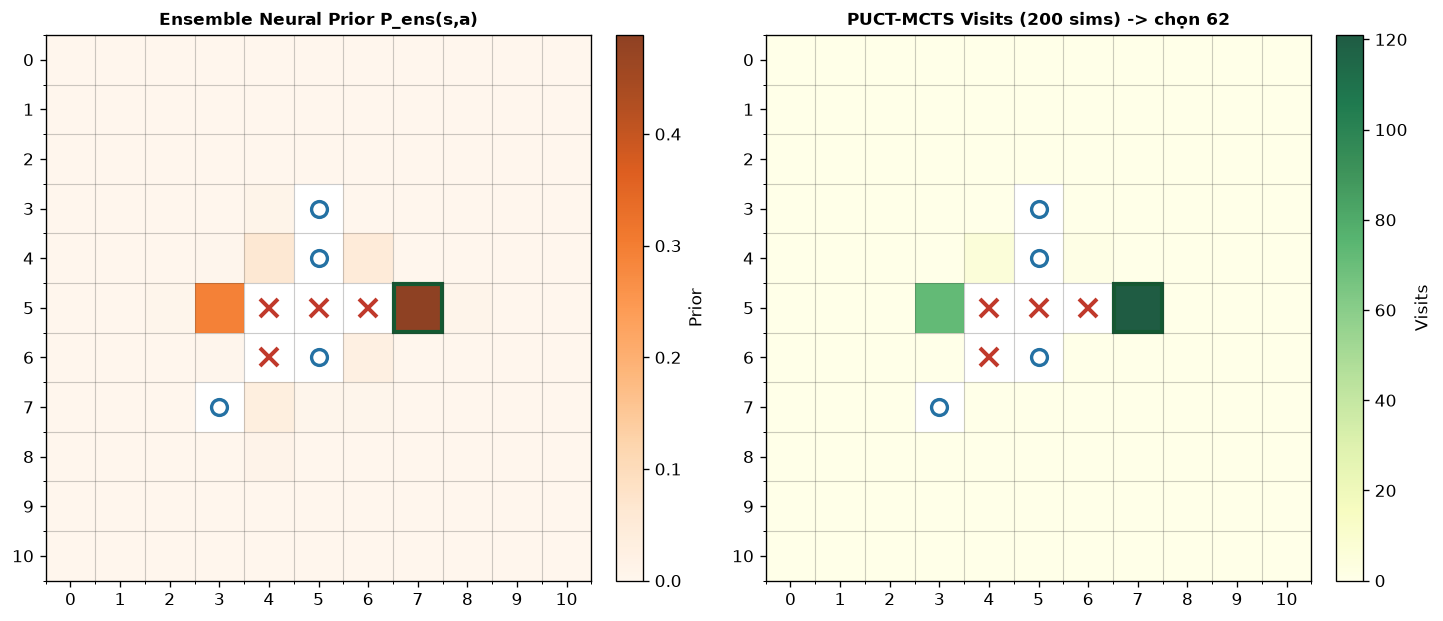

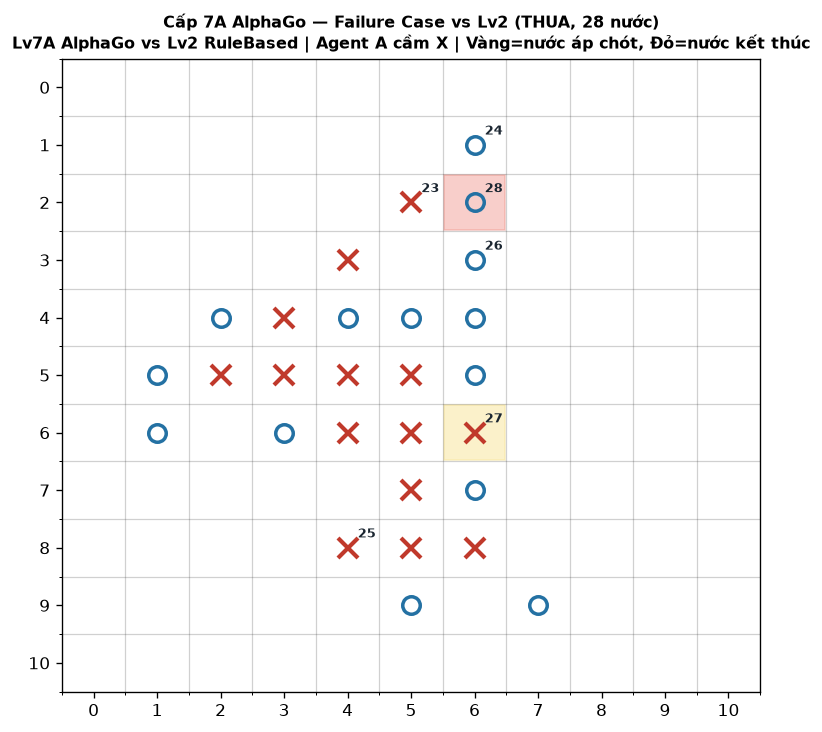

{'matchup': 'Lv7 AlphaGo vs Lv2 RuleBased',
 'game_index': 1,
 'agent_a': 'Level7_AlphaGo_PUCT',
 'agent_b': 'Rule-Based Heuristic Greedy Look-Ahead',
 'agent_a_side': 'X',
 'opening': [60, 48],
 'winner': 'O',
 'result_a': 'loss',
 'num_moves': 28,
 'avg_ms_a': 317.851,
 'p95_ms_a': 430.543,
 'avg_search_a': 135.38,
 'history': [60,
  48,
  58,
  61,
  70,
  50,
  82,
  46,
  94,
  106,
  71,
  49,
  47,
  69,
  59,
  83,
  57,
  56,
  37,
  67,
  93,
  104,
  27,
  17,
  92,
  39,
  72,
  28]}

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 5.2))
n = env_mid.board_size
visits_grid = np.zeros((n, n), dtype=np.float64)
prior_grid = np.zeros((n, n), dtype=np.float64)
for item in ag_demo.get_root_stats():
    visits_grid[item["row"], item["col"]] = item["visits"]
    prior_grid[item["row"], item["col"]] = item["prior"]

for ax, grid, title, cmap, clabel in [
    (axes[0], prior_grid, "Ensemble Neural Prior P_ens(s,a)", "Oranges", "Prior"),
    (axes[1], visits_grid, f"PUCT-MCTS Visits ({ag_demo.last_search_count} sims) -> chọn {chosen}", "YlGn", "Visits"),
]:
    masked = np.ma.masked_where(env_mid.board != 0, grid)
    im = ax.imshow(masked, cmap=cmap, origin="upper", alpha=0.88)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=clabel)
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#333333", linewidth=0.7)
    ax.grid(which="major", visible=False)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    for r in range(n):
        for c in range(n):
            v = int(env_mid.board[r, c])
            if v == 1:
                ax.plot(c, r, marker="x", markersize=11, markeredgewidth=2.4, color="#c0392b")
            elif v == -1:
                ax.plot(c, r, marker="o", markersize=9.5, markeredgewidth=2.0, markerfacecolor="none", color="#2471a3")
    hr, hc = divmod(int(chosen), n)
    ax.add_patch(plt.Rectangle((hc - 0.48, hr - 0.48), 0.96, 0.96, fill=False, edgecolor="#145a32", linewidth=2.5))
    ax.set_title(title, fontsize=10, fontweight="bold")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "07_level7_alphago_explainability.png", dpi=150, bbox_inches="tight")
plt.show()

# Failure Case Analysis trước Cấp 2 / Cấp 3
plot_failure_or_decisive_game(
    raw_logs_lv7,
    prefer_matchup="Lv2 RuleBased",
    title_prefix="Cấp 7 AlphaGo — Failure Case vs Lv2",
    save_path=FIGURES_DIR / "07_level7_failure_case.png",
)


## 6. Tóm tắt Kết luận & Hạn chế 
- **Trả lời câu hỏi nghiên cứu:** Ghép **Policy Cấp 5 + DQN Cấp 6** thành Ensemble Prior vào cây **PUCT-MCTS** tạo ra sức mạnh tổng hợp vượt trội hẳn từng thành phần: thắng **100%** trước `Pure CNN (Cấp 5)`, **90–100%** trước `Pure DQN (Cấp 6)`, **70–100%** trước `MCTS (Cấp 4)`, và **50–70%** trước `Minimax d=3 (Cấp 3)` trong giới hạn `<= 0.8s/nước` trên CPU.
- **Khả năng giải thích (Explainability):** Tách bạch trực quan giữa trực giác mạng nơ-ron (`prior`) và xác minh bằng cây tìm kiếm (`visits`, `q_mcts`), giúp dễ dàng giải thích vì sao AI bác bỏ nước có prior cao nhưng bị đối thủ phản đòn ở tầng sâu.
- **Hạn chế & Hướng phát triển:** Trên CPU đơn luồng, số simulations trong `0.8s` bị giới hạn ở ~`130–200` do mỗi lần mở rộng nút cần gọi 2 mạng riêng biệt; nếu hợp nhất thành **1 mạng 2-đầu `Policy+Value` (AlphaZero-lite Cấp 8)** kèm batching trên GPU sẽ tăng thông lượng gấp 3–5×.
